In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating the network

In [4]:
N = 1024
m = 2
k = 5

In [5]:
P = np.array([[0.59, 0.43], [0.43, 0.78]])
l = np.array([0.25, 0.75])

In [6]:
generator = MultifractalNetworkGenerator(P,l,k,N,num_workers=-1)

Initializing...
0.0008721351623535156


In [45]:
generator()
print(2 * generator.G.number_of_edges() / generator.G.number_of_nodes())

Initializing...
0.001005411148071289
Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 138.17it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 77.80it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 77.13it/s]

... (27 outputs left out)


100%|██████████| 32/32 [00:00<00:00, 74.73it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 73.58it/s]

111.177734375


Calculating betweenness...
Done.
Calculating node positions...
Done.


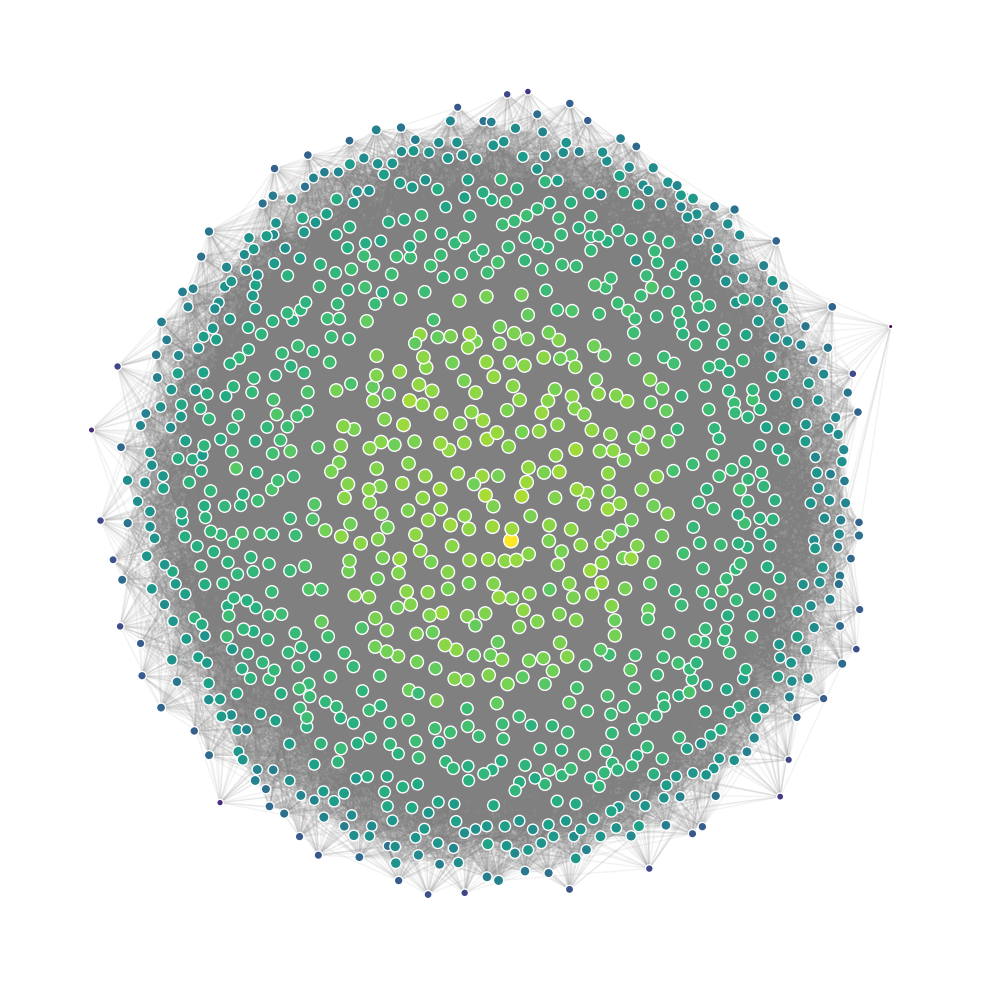

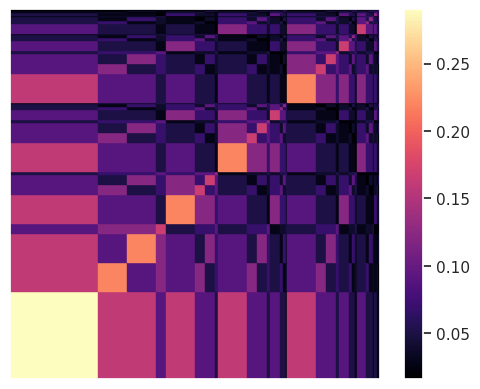

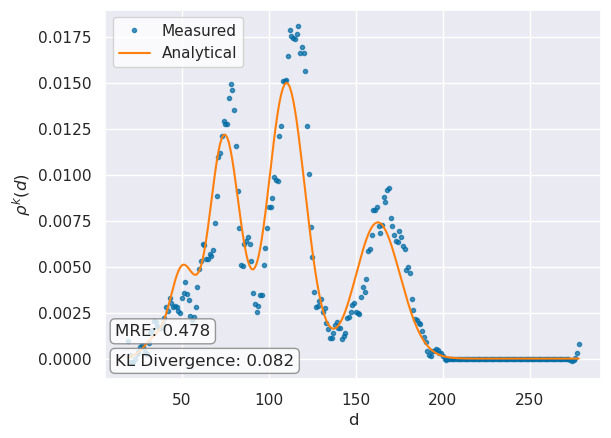

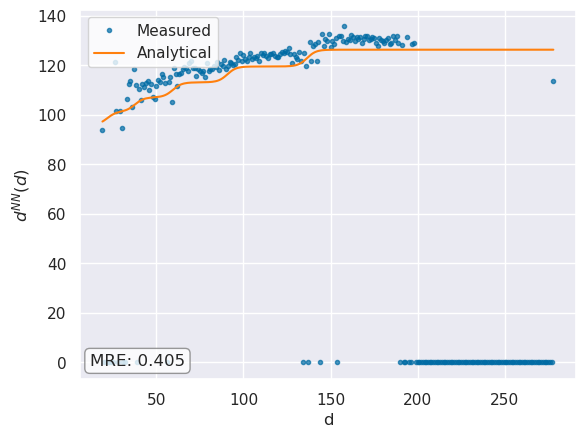

Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:20.121618
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:54:20.038351


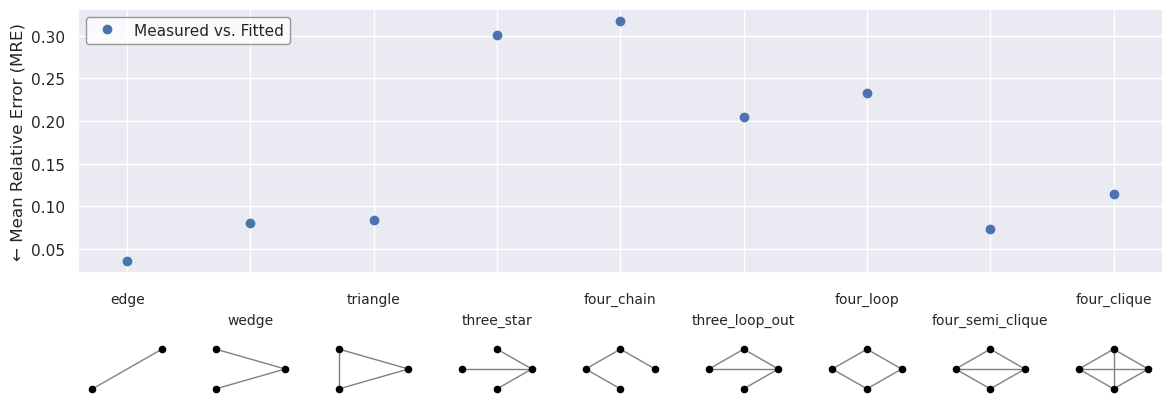

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'analytical_count': 54880.31575659009,
  'count': 56923,
  'MRE': 0.03588504195860916},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'analytical_count': 6580710.350378295,
  'count': 6052444,
  'MRE': 0.08027497371129969},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'analytical_count': 304876.6618656895,
  'count': 332737,
  'MRE': 0.08373080881991032},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'analytical_count': 286657978.81376827,
  'count': 200435629,
  'MRE': 0.3007847546074548},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'analytical_count': 799355175.2904582,
  'count': 545864993,


In [9]:
generator.plot_generated_network(
    layout_func = nx.kamada_kawai_layout,
    largest_component_only = False,
)

generator.network_stats(
    filename = "figures/synthetic_network_1k_plot_ground_truth.pdf",
    motif_analyzer_args = {
        'exact': True,
        'bootstrap_iters': None,
        'ci': None
    }
)

generator.motifs

In [47]:
generator.save_network('./test_networks/synthetic_network_1k.graphml')

# Fitting

## Load, count motifs

In [7]:
filename = './test_networks/synthetic_network_1k.graphml'
G = nx.read_graphml(filename)

In [10]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size**2))+1)

2  k_max:  6
3  k_max:  4
5  k_max:  3
6  k_max:  2
7  k_max:  2


In [11]:
mfnf = MultifractalNetworkFitter(G,
                                 d_range = [1,200],
                                 motifs = [
                                     {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
                                     {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
                                     {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
                                     {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
                                 ],
                                 sampling_ratios = {3: None,
                                                    4: None},
                                 motif_analyzer_args={'exact': True, 'bootstrap_iters': None, 'ci': None},
                                 population_size = 100,
                                 weights = {'rho':9,
                                            'deg_nn':9,
                                            'motifs':1,
                                            'edge':9},
                                 pre_loaded_motifs = './test_networks/synthetic_network_1k_motifs.pkl'
                                )

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Succesfully loaded motifs for network G from ./test_networks/synthetic_network_1k_motifs.pkl


In [64]:
mfnf.save_motifs('./test_networks/synthetic_network_1k_motifs.pkl')

## Grid Search - Find m,k,P,l together

In [65]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,   'k': [1,10]},
                {'m': 3,   'k': [1,6]},
               ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-18 08:42:02,369] A new study created in memory with name: no-name-676c5c52-3458-43c5-9808-cb29e9b79fc5


Grid Search requires 9 trials...


[I 2025-01-18 08:42:29,210] Trial 0 finished with value: 2.206103996347437 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 2.206103996347437.
[I 2025-01-18 08:42:46,634] Trial 1 finished with value: 2.39589566690285 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 2.206103996347437.
[I 2025-01-18 08:43:06,056] Trial 2 finished with value: 5.118579965426007 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 2.206103996347437.
[I 2025-01-18 08:43:22,994] Trial 3 finished with value: 2.1691501738109755 and parameters: {'m': 2, 'k': 5}. Best is trial 3 with value: 2.1691501738109755.
[I 2025-01-18 08:44:10,802] Trial 4 finished with value: 2.2242826434308207 and parameters: {'m': 2, 'k': 9}. Best is trial 3 with value: 2.1691501738109755.
[I 2025-01-18 08:44:31,856] Trial 5 finished with value: 2.185249496191799 and parameters: {'m': 2, 'k': 7}. Best is trial 3 with value: 2.1691501738109755.
[I 2025-01-18 08:44:50,224] Trial 6 finished with value: 2.1

Grid Search requires 5 trials...


[I 2025-01-18 08:46:10,852] Trial 0 finished with value: 2.096496651018646 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 2.096496651018646.
[I 2025-01-18 08:46:53,569] Trial 1 finished with value: 5.0964702244439195 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 2.096496651018646.
[I 2025-01-18 08:47:34,701] Trial 2 finished with value: 2.110691686533772 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 2.096496651018646.
[I 2025-01-18 08:48:15,841] Trial 3 finished with value: 2.129202621154468 and parameters: {'m': 3, 'k': 4}. Best is trial 0 with value: 2.096496651018646.
[I 2025-01-18 08:49:18,999] Trial 4 finished with value: 2.1628874984759197 and parameters: {'m': 3, 'k': 5}. Best is trial 0 with value: 2.096496651018646.


Best parameters:  {'m': 3, 'k': 3}
Best energy:  4.237417057992849
Best KL-divergence:  0.028821584049323862
Best KLD augumented energy: 2.096496651018646
Best P matrix:
 [[0.66068829 0.36442837 0.16133932]
 [0.36442837 0.3891802  0.20633046]
 [0.16133932 0.20633046 0.98064057]]
Best l vector:
 [0.62443321 0.35897793 0.01658886]


### Looking at 'close contenders'
Other m-k cominations that resulted in an energy close to the 'best' one.

#### 2-4

Energy: 4.580233421593711
KL-divergence: 0.03500084641956247
KLD augumented energy: 2.156346595957177
[[0.7298076  0.40649228]
 [0.40649228 0.47088023]]
[0.70826781 0.29173219]


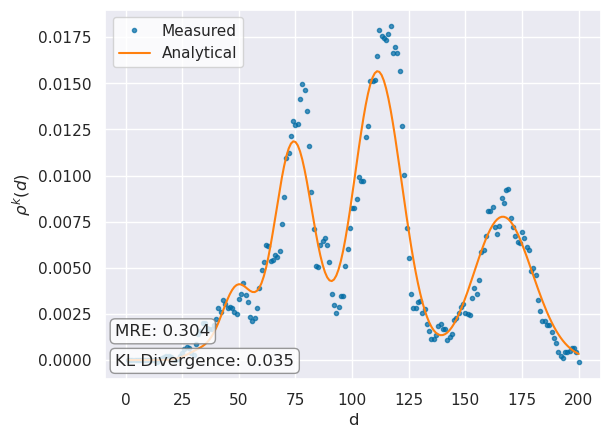

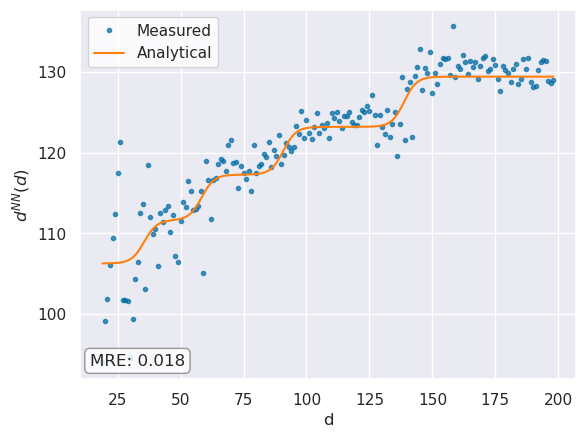

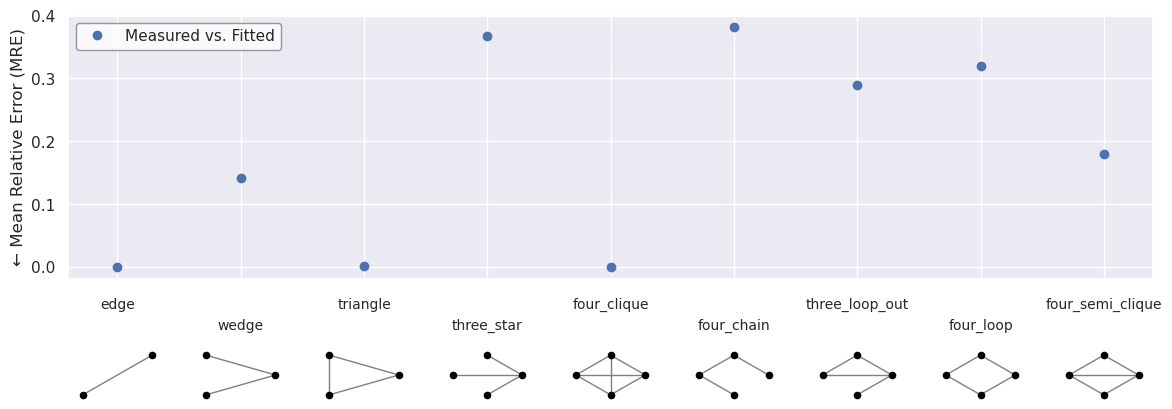

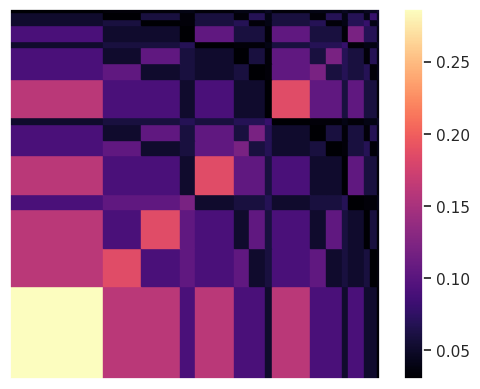

In [73]:
M = 2
K = 4
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)

#### 2-5

Energy: 4.461877156652898
KL-divergence: 0.03193056223248276
KLD augumented energy: 2.169682658551557
[[0.77640928 0.4410665 ]
 [0.4410665  0.54995277]]
[0.75930111 0.24069889]


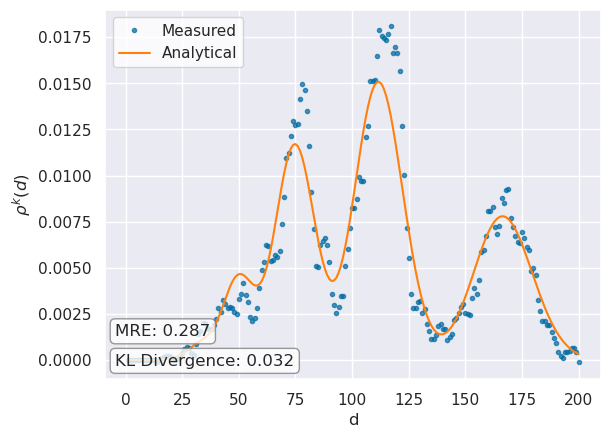

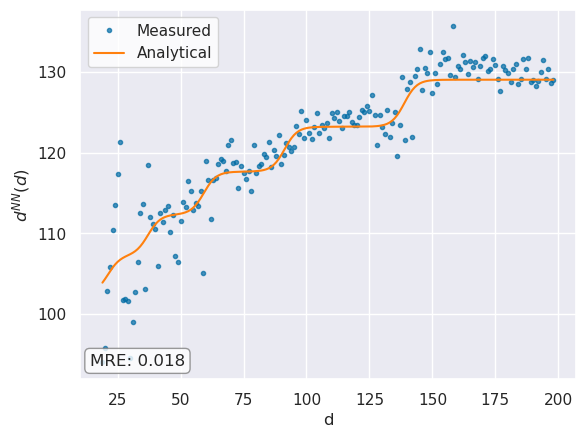

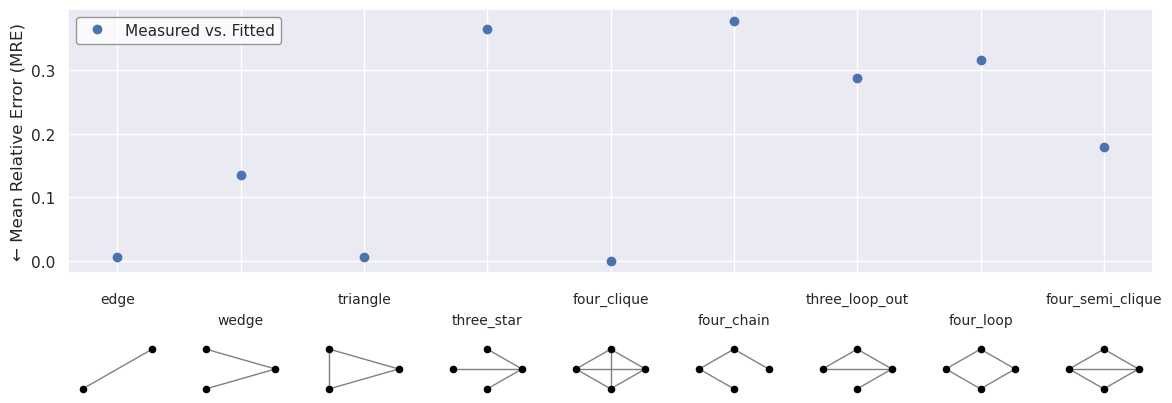

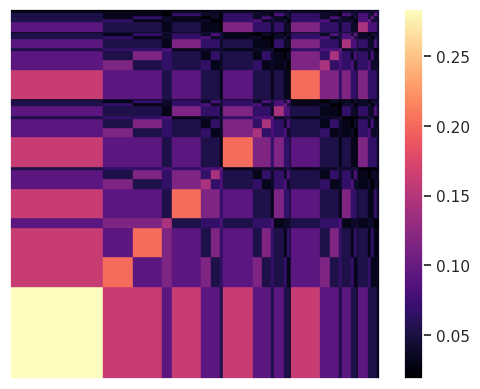

In [7]:
M = 2
K = 5
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot.pdf"
)

#### 3-3

Energy: 4.23992164399635
KL-divergence: 0.02881136444522354
KLD augumented energy: 2.0989593421552595
[[0.66072276 0.36408371 0.16525543]
 [0.36408371 0.39009631 0.19877346]
 [0.16525543 0.19877346 0.99847026]]
[0.62453411 0.3588566  0.01660929]


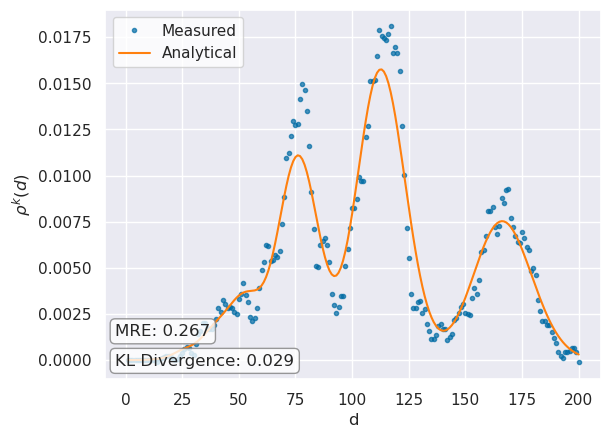

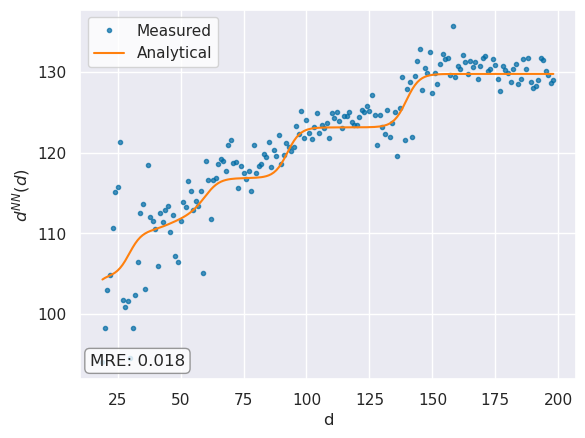

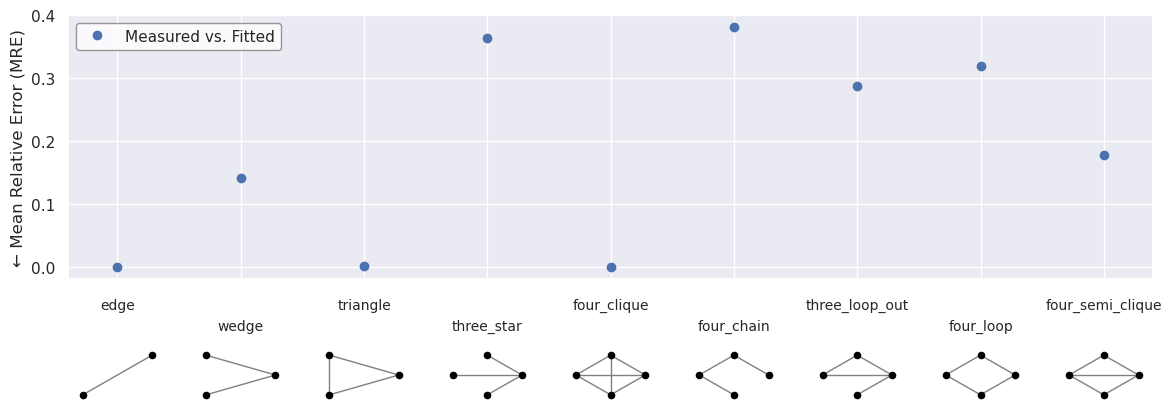

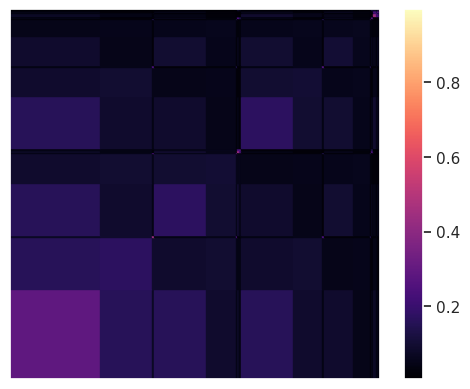

In [7]:
M = 3
K = 3
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_3_3.pdf"
)

#### 3-5

Energy: 4.334045950617076
KL-divergence: 0.031522801345301145
KLD augumented energy: 2.158553374282764
[[0.77547129 0.44754691 0.12994538]
 [0.44754691 0.5501688  0.55554486]
 [0.12994538 0.55554486 0.48879093]]
[0.75911593 0.23774957 0.0031345 ]


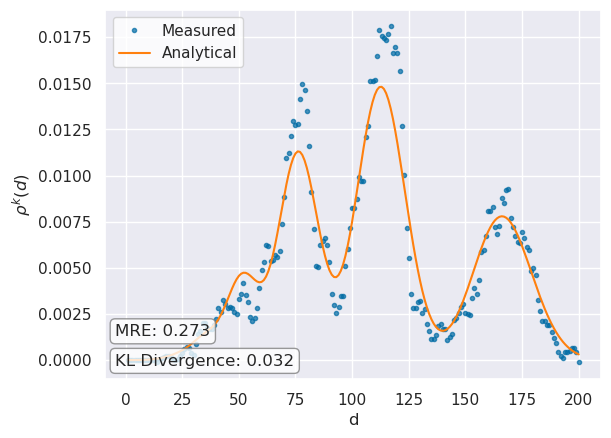

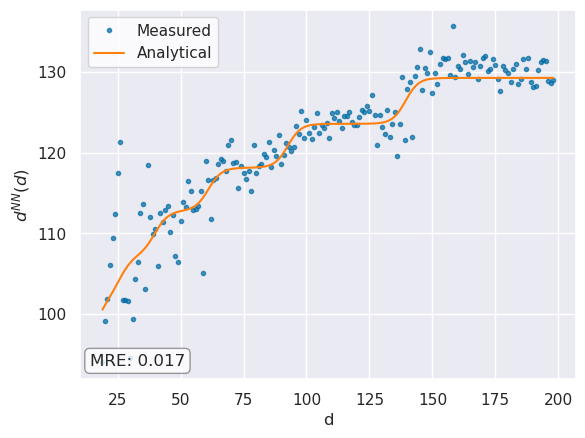

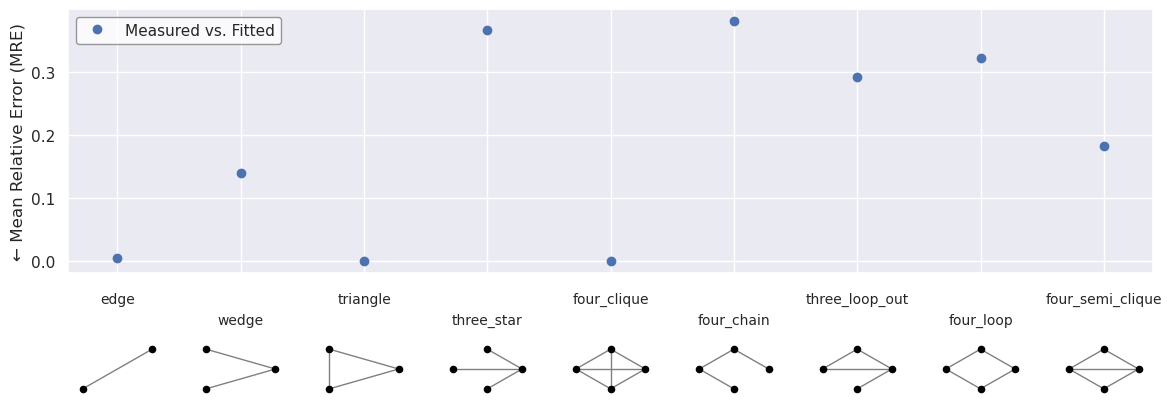

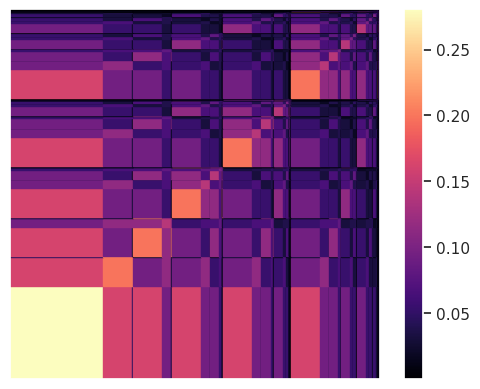

In [78]:
M = 3
K = 5
mfnf.find_P_l(m = M, k = K, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)

## Variant Generation

In [12]:
M = 2
K = 5
mfnf.find_P_l(m = M, k = K, one_shot=True)

Energy: 4.462852336417978
KL-divergence: 0.03190912131340571
KLD augumented energy: 2.1710649708181875


Initializing...
0.0009105205535888672
Calculating betweenness...
Done.
Calculating node positions...
Done.


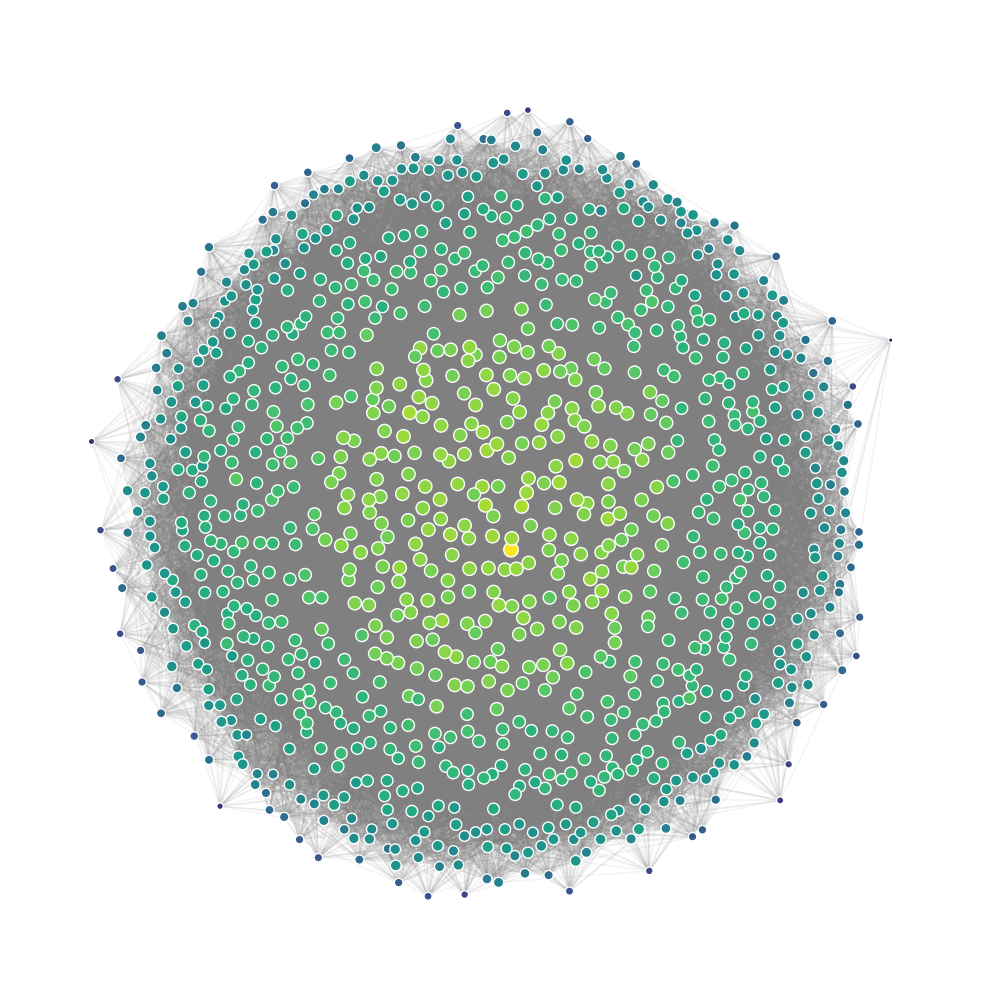

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 101.69it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 55.11it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 46.67it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 55.36it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 57.90it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


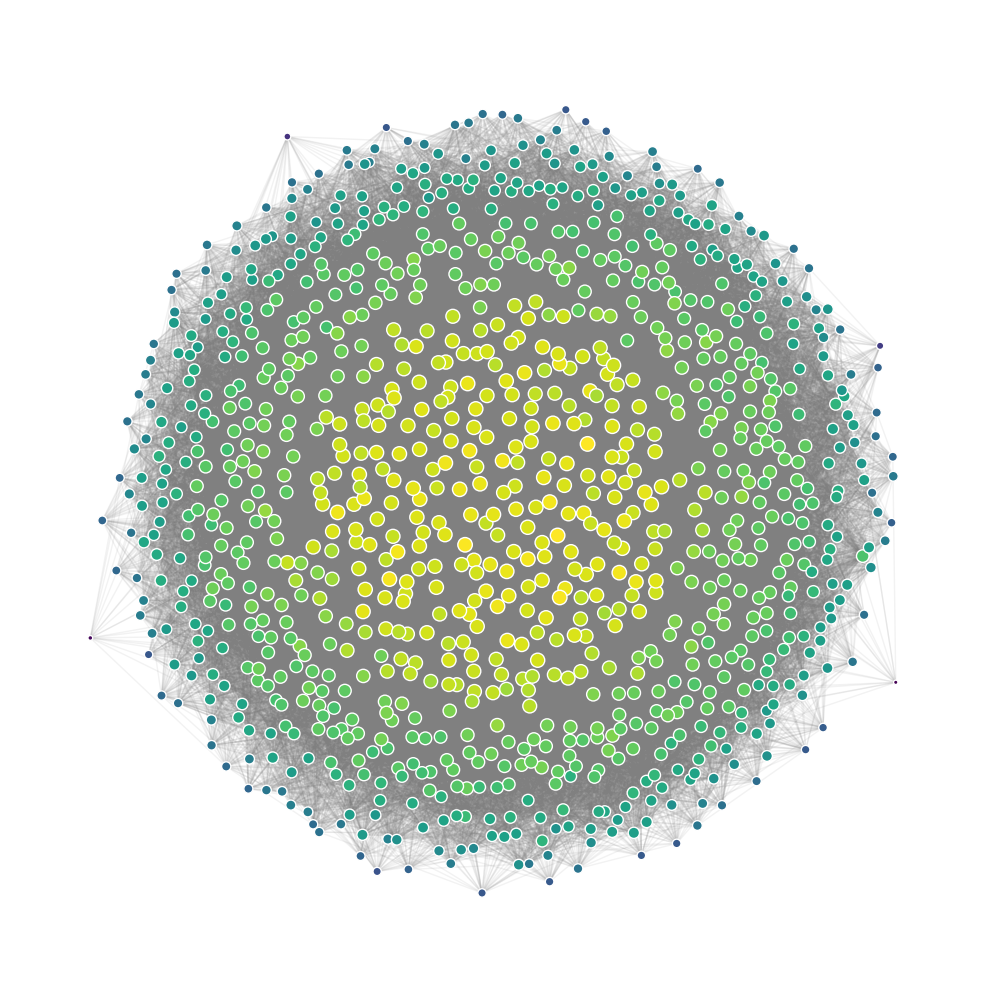

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 130.86it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 62.11it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 60.22it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


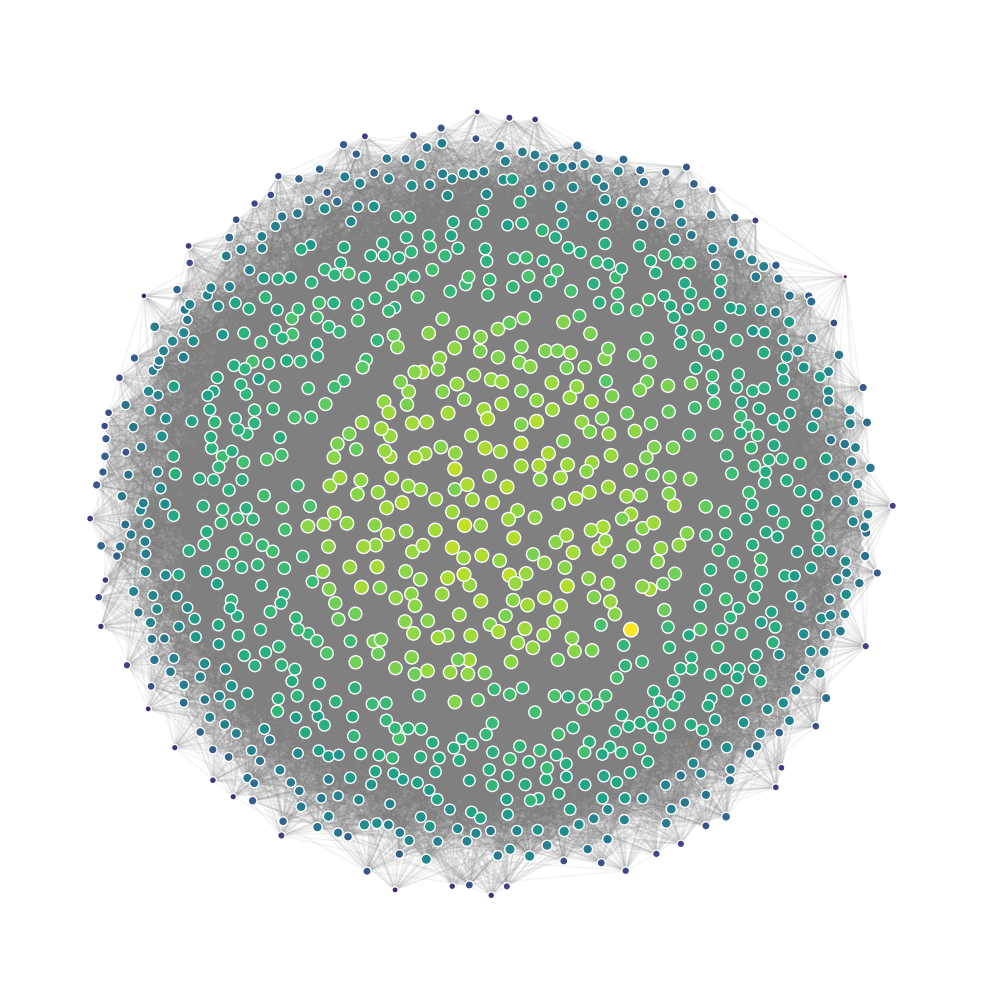

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 144.51it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 67.64it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


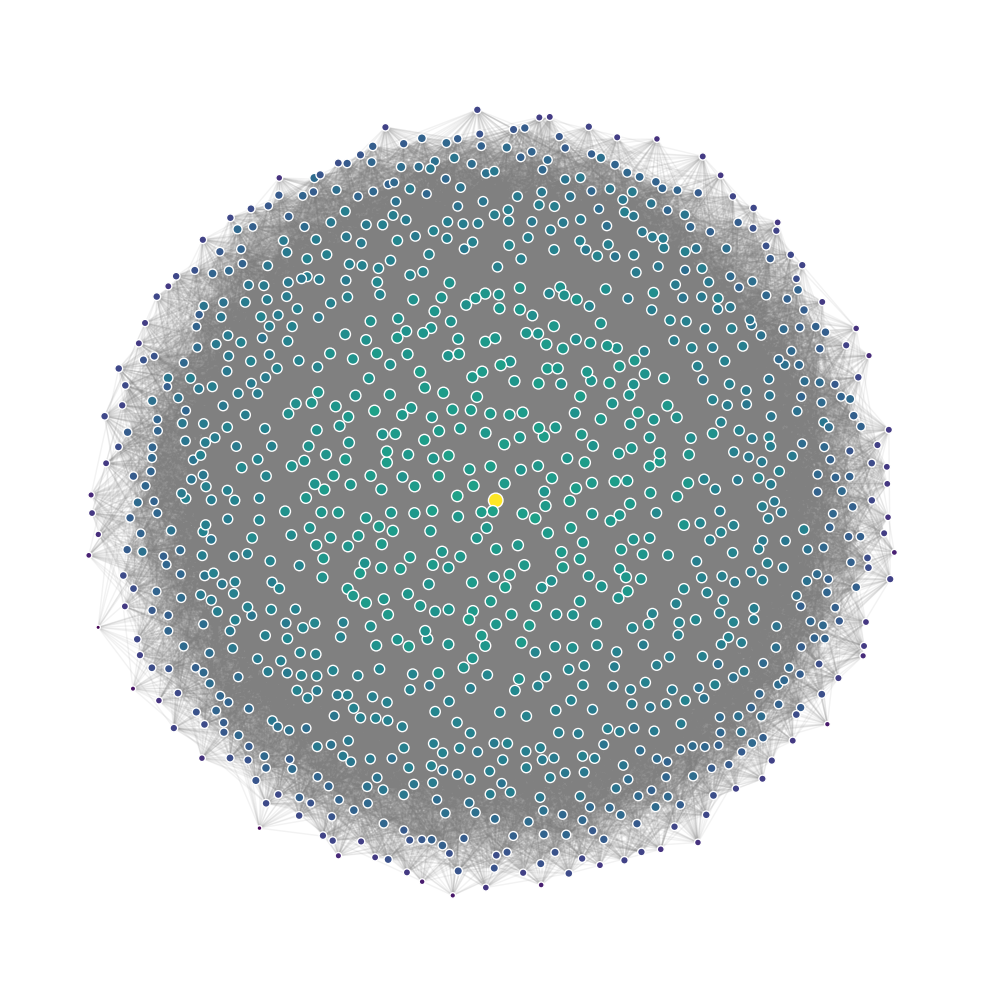

In [13]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  None #"figures/synthetic_network_1k_variants.pdf"
    },
    filename = None #"variant_networks/synthetic_network_1k_variants.graphml"
)